Saved DDL to: C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION\04_1_schema_ddl.sql

Source Rows: 968,294 | Columns: 12
                     Column   Dtype  Null_Count  Null_Pct
        Global_active_power float64         466    0.0481
      Global_reactive_power float64         466    0.0481
                    Voltage float64         466    0.0481
           Global_intensity float64         466    0.0481
             Sub_metering_1 float64         466    0.0481
             Sub_metering_2 float64         466    0.0481
             Sub_metering_3 float64         466    0.0481
              GAP_Indicator   int64           0    0.0000
Global_active_power_imputed float64           1    0.0001
       Outlier_Flag_Extreme   int64           0    0.0000
   Derived_Active_Energy_Wh float64         466    0.0481
    Sub_metering_4_Residual float64         466    0.0481


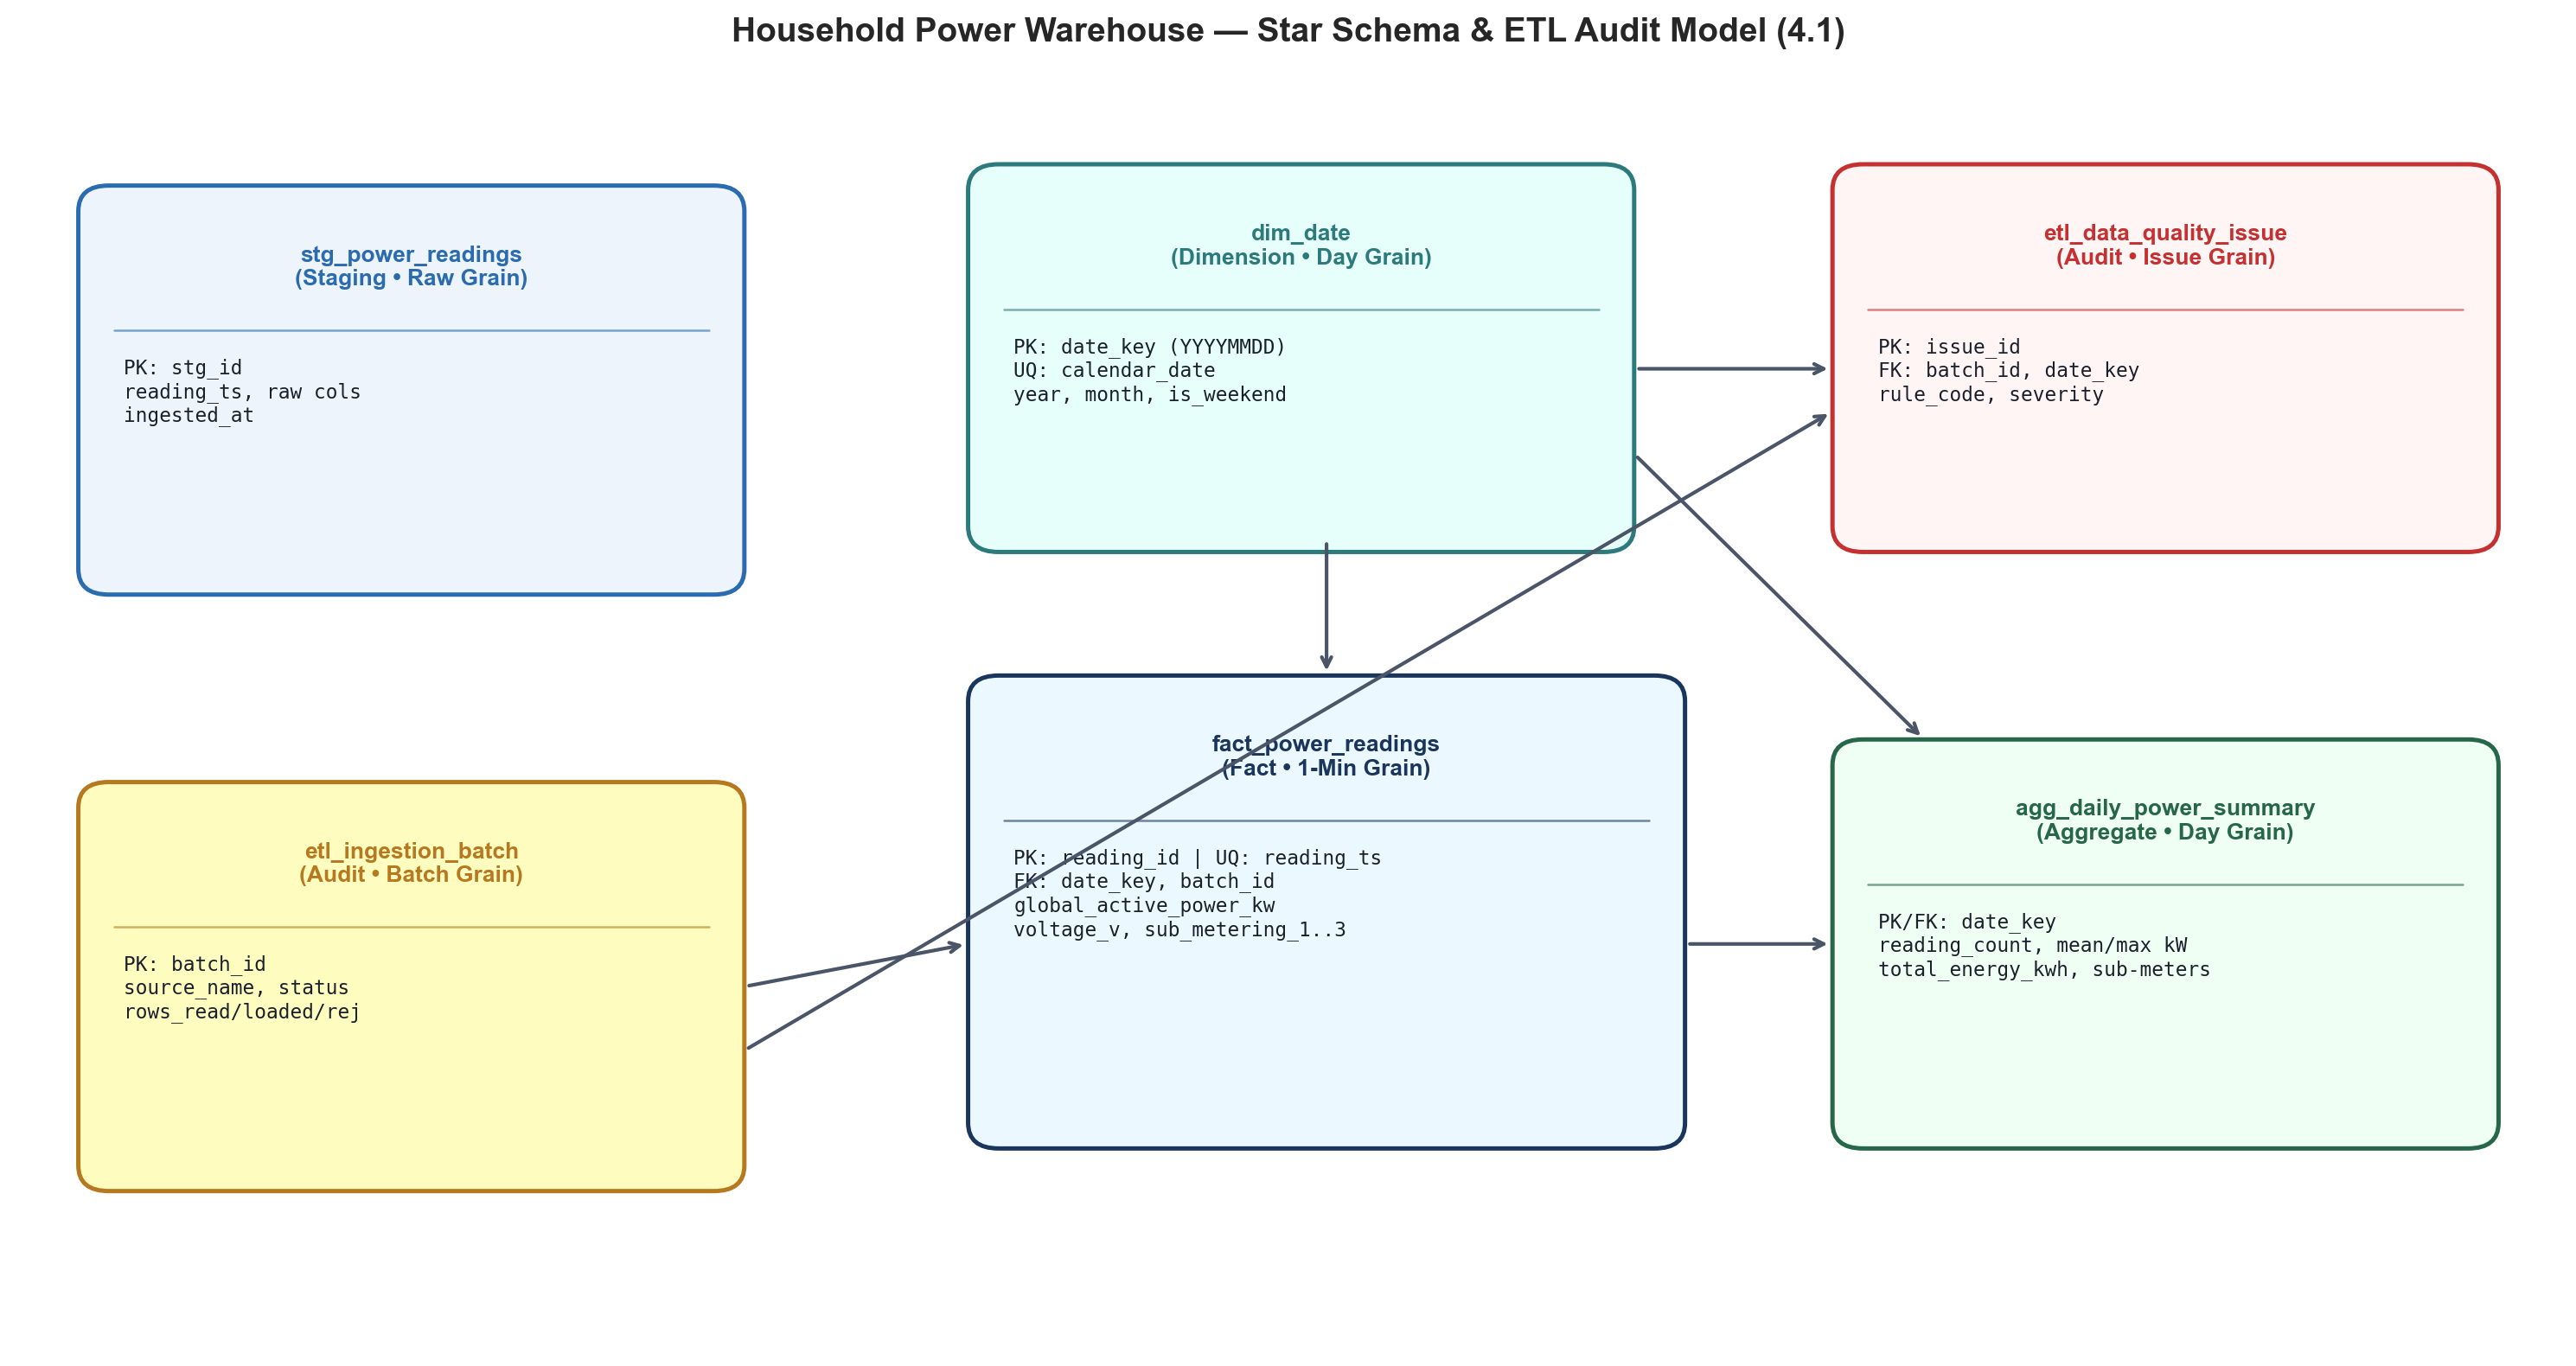

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PROJECT_ROOT = Path(
    r"C:\Users\USER\OneDrive\New folder\Desktop\KENYA_HOUSEHOLD_ELECTRIC_POWER_CONSUMPTION"
)
PARQUET_PATH = PROJECT_ROOT / "cleaned_household_power.parquet"

# --- 1. DDL Script (MySQL 8.0) ---
ddl_sql = """
CREATE DATABASE IF NOT EXISTS kenya_power_dw
  CHARACTER SET utf8mb4
  COLLATE utf8mb4_0900_ai_ci;
USE kenya_power_dw;

-- 1. Staging Table (Raw / Pre-Validation Landing)
CREATE TABLE IF NOT EXISTS stg_power_readings (
    stg_id BIGINT UNSIGNED AUTO_INCREMENT PRIMARY KEY,
    source_file VARCHAR(255) NOT NULL,
    raw_datetime_str VARCHAR(64) NOT NULL,
    reading_ts DATETIME NULL,
    global_active_power DOUBLE NULL,
    global_reactive_power DOUBLE NULL,
    voltage DOUBLE NULL,
    global_intensity DOUBLE NULL,
    sub_metering_1 DOUBLE NULL,
    sub_metering_2 DOUBLE NULL,
    sub_metering_3 DOUBLE NULL,
    ingested_at TIMESTAMP NOT NULL DEFAULT CURRENT_TIMESTAMP,
    KEY idx_stg_reading_ts (reading_ts)
);

-- 2. Ingestion Batch Control Table
CREATE TABLE IF NOT EXISTS etl_ingestion_batch (
    batch_id BIGINT UNSIGNED AUTO_INCREMENT PRIMARY KEY,
    source_name VARCHAR(255) NOT NULL,
    started_at DATETIME NOT NULL,
    finished_at DATETIME NULL,
    status VARCHAR(32) NOT NULL DEFAULT 'RUNNING',
    rows_read BIGINT UNSIGNED NOT NULL DEFAULT 0,
    rows_loaded BIGINT UNSIGNED NOT NULL DEFAULT 0,
    rows_rejected BIGINT UNSIGNED NOT NULL DEFAULT 0,
    CONSTRAINT chk_batch_status CHECK (status IN ('RUNNING', 'SUCCESS', 'FAILED', 'PARTIAL'))
);

-- 3. Calendar Date Dimension
CREATE TABLE IF NOT EXISTS dim_date (
    date_key INT UNSIGNED PRIMARY KEY,
    calendar_date DATE NOT NULL,
    year_num SMALLINT UNSIGNED NOT NULL,
    quarter_num TINYINT UNSIGNED NOT NULL,
    month_num TINYINT UNSIGNED NOT NULL,
    month_name VARCHAR(16) NOT NULL,
    day_of_month TINYINT UNSIGNED NOT NULL,
    day_of_week TINYINT UNSIGNED NOT NULL,
    day_name VARCHAR(16) NOT NULL,
    is_weekend TINYINT(1) NOT NULL,
    CONSTRAINT uq_dim_date UNIQUE (calendar_date),
    CONSTRAINT chk_is_weekend CHECK (is_weekend IN (0, 1))
);

-- 4. Fact Table: 1-Minute Household Power Readings
CREATE TABLE IF NOT EXISTS fact_power_readings (
    reading_id BIGINT UNSIGNED AUTO_INCREMENT PRIMARY KEY,
    reading_ts DATETIME NOT NULL,
    date_key INT UNSIGNED NOT NULL,
    batch_id BIGINT UNSIGNED NOT NULL,
    global_active_power_kw DECIMAL(10, 4) NOT NULL,
    global_reactive_power_kvar DECIMAL(10, 4) NULL,
    voltage_v DECIMAL(8, 3) NULL,
    global_intensity_a DECIMAL(8, 3) NULL,
    sub_metering_1_wh DECIMAL(10, 3) NULL,
    sub_metering_2_wh DECIMAL(10, 3) NULL,
    sub_metering_3_wh DECIMAL(10, 3) NULL,
    CONSTRAINT uq_fact_reading_ts UNIQUE (reading_ts),
    CONSTRAINT chk_active_power_nonneg CHECK (global_active_power_kw >= 0),
    CONSTRAINT chk_voltage_pos CHECK (voltage_v IS NULL OR voltage_v > 0),
    CONSTRAINT fk_fact_date FOREIGN KEY (date_key) REFERENCES dim_date (date_key),
    CONSTRAINT fk_fact_batch FOREIGN KEY (batch_id) REFERENCES etl_ingestion_batch (batch_id),
    KEY idx_fact_date_ts (date_key, reading_ts),
    KEY idx_fact_batch (batch_id)
);

-- 5. Data Quality Issue Log
CREATE TABLE IF NOT EXISTS etl_data_quality_issue (
    issue_id BIGINT UNSIGNED AUTO_INCREMENT PRIMARY KEY,
    batch_id BIGINT UNSIGNED NOT NULL,
    date_key INT UNSIGNED NULL,
    reading_ts DATETIME NULL,
    column_name VARCHAR(64) NULL,
    rule_code VARCHAR(64) NOT NULL,
    severity VARCHAR(16) NOT NULL DEFAULT 'WARN',
    issue_detail VARCHAR(500) NULL,
    detected_at TIMESTAMP NOT NULL DEFAULT CURRENT_TIMESTAMP,
    CONSTRAINT chk_dq_severity CHECK (severity IN ('INFO', 'WARN', 'ERROR')),
    CONSTRAINT fk_dq_batch FOREIGN KEY (batch_id) REFERENCES etl_ingestion_batch (batch_id),
    CONSTRAINT fk_dq_date FOREIGN KEY (date_key) REFERENCES dim_date (date_key),
    KEY idx_dq_batch_rule (batch_id, rule_code),
    KEY idx_dq_date (date_key)
);

-- 6. Daily Aggregate Table (One Row per Calendar Day)
CREATE TABLE IF NOT EXISTS agg_daily_power_summary (
    date_key INT UNSIGNED PRIMARY KEY,
    reading_count INT UNSIGNED NOT NULL,
    mean_active_power_kw DECIMAL(10, 4) NOT NULL,
    max_active_power_kw DECIMAL(10, 4) NOT NULL,
    total_energy_kwh DECIMAL(12, 4) NOT NULL,
    mean_voltage_v DECIMAL(8, 3) NULL,
    total_sub_meter_1_wh DECIMAL(12, 3) NULL,
    total_sub_meter_2_wh DECIMAL(12, 3) NULL,
    total_sub_meter_3_wh DECIMAL(12, 3) NULL,
    CONSTRAINT fk_agg_date FOREIGN KEY (date_key) REFERENCES dim_date (date_key)
);
""".strip()

ddl_file = PROJECT_ROOT / "04_1_schema_ddl.sql"
ddl_file.write_text(ddl_sql, encoding="utf-8")
print(f"Saved DDL to: {ddl_file}")

# --- 2. Source Dataset Profile (Row Count & Nulls) ---
if PARQUET_PATH.exists():
    df_src = pd.read_parquet(PARQUET_PATH)
    null_profile = pd.DataFrame({
        "Column": df_src.columns,
        "Dtype": [str(df_src[c].dtype) for c in df_src.columns],
        "Null_Count": [int(df_src[c].isna().sum()) for c in df_src.columns],
        "Null_Pct": [round(float(df_src[c].isna().mean() * 100), 4) for c in df_src.columns],
    })
    print(f"\nSource Rows: {len(df_src):,} | Columns: {df_src.shape[1]}")
    print(null_profile.to_string(index=False))
else:
    print(f"\nParquet not found at {PARQUET_PATH}; skipped live row/null profile.")

# --- 3. Schema / ERD Diagram ---
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig, ax = plt.subplots(figsize=(15, 8), dpi=200)
ax.set_xlim(0, 100)
ax.set_ylim(0, 60)
ax.axis("off")
ax.set_title("Household Power Warehouse — Star Schema & ETL Audit Model (4.1)", fontsize=14, fontweight="bold", pad=12)

tables = [
    ("stg_power_readings\n(Staging • Raw Grain)", 3, 36, 25, 18, "#eef4fb", "#2b6cb0",
     "PK: stg_id\nreading_ts, raw cols\ningested_at"),
    ("etl_ingestion_batch\n(Audit • Batch Grain)", 3, 8, 25, 18, "#fefcbf", "#b7791f",
     "PK: batch_id\nsource_name, status\nrows_read/loaded/rej"),
    ("dim_date\n(Dimension • Day Grain)", 38, 38, 25, 17, "#e6fffa", "#2c7a7b",
     "PK: date_key (YYYYMMDD)\nUQ: calendar_date\nyear, month, is_weekend"),
    ("fact_power_readings\n(Fact • 1-Min Grain)", 38, 10, 27, 21, "#ebf8ff", "#1a365d",
     "PK: reading_id | UQ: reading_ts\nFK: date_key, batch_id\nglobal_active_power_kw\nvoltage_v, sub_metering_1..3"),
    ("etl_data_quality_issue\n(Audit • Issue Grain)", 72, 38, 25, 17, "#fff5f5", "#c53030",
     "PK: issue_id\nFK: batch_id, date_key\nrule_code, severity"),
    ("agg_daily_power_summary\n(Aggregate • Day Grain)", 72, 10, 25, 18, "#f0fff4", "#276749",
     "PK/FK: date_key\nreading_count, mean/max kW\ntotal_energy_kwh, sub-meters"),
]

for title, x, y, w, h, fc, ec, body in tables:
    box = FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.6,rounding_size=1.2",
                         facecolor=fc, edgecolor=ec, linewidth=1.8)
    ax.add_patch(box)
    ax.text(x + w / 2, y + h - 2.2, title, ha="center", va="top", fontsize=9.5, fontweight="bold", color=ec)
    ax.plot([x + 0.8, x + w - 0.8], [y + h - 6.2, y + h - 6.2], color=ec, lw=0.9, alpha=0.6)
    ax.text(x + 1.2, y + h - 7.5, body, ha="left", va="top", fontsize=8.2, color="#1a202c", family="monospace")

# Relationship arrows
arrows = [
    ((51.5, 38), (51.5, 31.6)),   # dim_date -> fact_power_readings
    ((28.6, 17), (37.4, 19)),     # etl_ingestion_batch -> fact_power_readings
    ((28.6, 14), (71.4, 44)),     # etl_ingestion_batch -> etl_data_quality_issue
    ((63.6, 46), (71.4, 46)),     # dim_date -> etl_data_quality_issue
    ((65.6, 19), (71.4, 19)),     # fact_power_readings -> agg_daily_power_summary
    ((63.6, 42), (75.0, 28.6)),   # dim_date -> agg_daily_power_summary
]
for (x1, y1), (x2, y2) in arrows:
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle="->", color="#4a5568", lw=1.5, shrinkA=2, shrinkB=2))

plt.tight_layout()
plt.show()